<a href="https://colab.research.google.com/github/akshaya-e/Lead-Conversion-Prediction-using-ML/blob/main/Lead_Conversion_Prediction.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

IMPORTING LIBRARIES & ML MODELS

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer

In [3]:
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

In [57]:
from sklearn.metrics import (accuracy_score,precision_score,recall_score,f1_score,roc_auc_score,confusion_matrix,classification_report,ConfusionMatrixDisplay,RocCurveDisplay)

In [5]:
import warnings
warnings.filterwarnings('ignore')

In [6]:
sns.set_theme(style="whitegrid")
print("All libraries imported successfully!")

All libraries imported successfully!


UPLOAD THE DATASET AND READ CSV FILE



In [7]:
from google.colab import files
uploaded = files.upload()

Saving Unified_Leads.csv to Unified_Leads.csv


In [8]:
df = pd.read_csv('Unified_Leads.csv')


UNDERSTAND THE DATASET

In [9]:
display(df.head())

,Name,contact_number,Contact_email,creation_date,first_call_attempt,lead_status,lead_stage,lead_tag,assigned_to,last_call_date,last_call_time,references,campaign_name,source_type,source_name
0,Anjali Singh,9931980478,anjali.singh878@hotmail.com,03-02-2026 22:31,NaN,PENDING WITH EXECUTIVE,Prospect,NaN,Anshad,NaN,NaN,NaN,Data Analytics Knovista,INSTAGRAM,INSTAGRAM
1,Kiran Bose,6474315136,kiran.bose601@example.com,03-02-2026 21:46,NaN,PENDING WITH EXECUTIVE,Prospect,NaN,Anshad,NaN,NaN,NaN,Data Analytics Knovista,FACEBOOK_ADS,FACEBOOK_ADS
2,Karthik Malhotra,6753707898,karthik.malhotra329@example.com,03-02-2026 21:28,NaN,PENDING WITH EXECUTIVE,Prospect,NaN,Anshad,NaN,NaN,NaN,Data Analytics Knovista,INSTAGRAM,INSTAGRAM
3,Anjali Sharma,9439163624,anjali.sharma85@example.com,03-02-2026 19:59,NaN,PENDING WITH EXECUTIVE,Prospect,NaN,Anshad,NaN,NaN,NaN,Data Analytics Knovista,INSTAGRAM,INSTAGRAM
4,Sneha Kapoor,9878269840,sneha.kapoor46@gmail.com,03-02-2026 19:19,NaN,PENDING WITH EXECUTIVE,Prospect,NaN,Anshad,NaN,NaN,NaN,Data Analytics Knovista,INSTAGRAM,INSTAGRAM


In [10]:
display(df.tail())

,Name,contact_number,Contact_email,creation_date,first_call_attempt,lead_status,lead_stage,lead_tag,assigned_to,last_call_date,last_call_time,references,campaign_name,source_type,source_name
27370,Rohit Reddy,6992973331,rohit.reddy220@hotmail.com,02-06-2025 13:14,02-06-2025 14:46,CLOSED,LOST,not-interested,Riswana,02-06-2025 14:46,2:46 PM,NaN,Business Accounting,INSTAGRAM,INSTAGRAM
27371,Kiran Shetty,9410734029,kiran.shetty925@outlook.com,02-06-2025 13:05,NaN,CLOSED,LOST,lost-to-competition,Anshad,NaN,NaN,NaN,Business Accounting,INSTAGRAM,INSTAGRAM
27372,Neha Shetty,9508547875,neha.shetty6@example.com,02-06-2025 12:39,02-06-2025 13:13,CLOSED,CONVERTED,NaN,Anshad,02-06-2025 13:13,1:13 PM,NaN,Business Accounting,INSTAGRAM,INSTAGRAM
27373,Nikhil Yadav,7870690595,nikhil.yadav620@outlook.com,02-06-2025 12:35,02-06-2025 13:01,RESCHEDULED BY EXECUTIVE,Follow Up Required,cold,Anshad,02-06-2025 13:01,1:01 PM,NaN,Business Accounting,INSTAGRAM,INSTAGRAM
27374,Nikhil Reddy,8750283113,nikhil.reddy172@gmail.com,02-06-2025 12:35,02-06-2025 14:33,RESCHEDULED BY EXECUTIVE,Follow Up Required,cold,Anshad,02-06-2025 14:33,2:33 PM,NaN,Business Accounting,INSTAGRAM,INSTAGRAM


In [11]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 27375 entries, 0 to 27374
Data columns (total 15 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   Name                27375 non-null  object 
 1   contact_number      27375 non-null  int64  
 2   Contact_email       27375 non-null  object 
 3   creation_date       27375 non-null  object 
 4   first_call_attempt  20646 non-null  object 
 5   lead_status         27375 non-null  object 
 6   lead_stage          27375 non-null  object 
 7   lead_tag            15959 non-null  object 
 8   assigned_to         27375 non-null  object 
 9   last_call_date      20646 non-null  object 
 10  last_call_time      20646 non-null  object 
 11  references          0 non-null      float64
 12  campaign_name       27375 non-null  object 
 13  source_type         27375 non-null  object 
 14  source_name         27375 non-null  object 
dtypes: float64(1), int64(1), object(13)
memory usage: 3.1

In [12]:
df.shape

(27375, 15)

In [13]:
df.columns.to_list()

['Name',
 'contact_number',
 'Contact_email',
 'creation_date',
 'first_call_attempt',
 'lead_status',
 'lead_stage',
 'lead_tag',
 'assigned_to',
 'last_call_date',
 'last_call_time',
 'references',
 'campaign_name',
 'source_type',
 'source_name']

In [14]:
df.describe()

,contact_number,references
count,2.737500e+04,0.0
mean,7.993886e+09,NaN
std,1.155797e+09,NaN
min,6.000027e+09,NaN
25%,6.991392e+09,NaN
50%,7.993050e+09,NaN
75%,8.996705e+09,NaN
max,9.999844e+09,NaN


CHECK MISSING VALUES

In [15]:
missing_values=df.isnull().sum()
print(missing_values)

Name                      0
contact_number            0
Contact_email             0
creation_date             0
first_call_attempt     6729
lead_status               0
lead_stage                0
lead_tag              11416
assigned_to               0
last_call_date         6729
last_call_time         6729
references            27375
campaign_name             0
source_type               0
source_name               0
dtype: int64


In [16]:
missing_percentage=df.isnull().sum() / len(df) * 100
print(missing_percentage)

Name                    0.000000
contact_number          0.000000
Contact_email           0.000000
creation_date           0.000000
first_call_attempt     24.580822
lead_status             0.000000
lead_stage              0.000000
lead_tag               41.702283
assigned_to             0.000000
last_call_date         24.580822
last_call_time         24.580822
references            100.000000
campaign_name           0.000000
source_type             0.000000
source_name             0.000000
dtype: float64


In [17]:
missing_df=pd.DataFrame({'Missing Values':missing_values,'Missing Percentage':missing_percentage})
print(missing_df)

                    Missing Values  Missing Percentage
Name                             0            0.000000
contact_number                   0            0.000000
Contact_email                    0            0.000000
creation_date                    0            0.000000
first_call_attempt            6729           24.580822
lead_status                      0            0.000000
lead_stage                       0            0.000000
lead_tag                     11416           41.702283
assigned_to                      0            0.000000
last_call_date                6729           24.580822
last_call_time                6729           24.580822
references                   27375          100.000000
campaign_name                    0            0.000000
source_type                      0            0.000000
source_name                      0            0.000000


In [18]:
missing_df.sort_values(by='Missing Values',ascending=False)

,Missing Values,Missing Percentage
references,27375,100.000000
lead_tag,11416,41.702283
first_call_attempt,6729,24.580822
last_call_date,6729,24.580822
last_call_time,6729,24.580822
contact_number,0,0.000000
Name,0,0.000000
lead_stage,0,0.000000
lead_status,0,0.000000
creation_date,0,0.000000


DATA CLEANING

In [19]:
df = df.copy()

In [20]:
df.drop_duplicates()



,Name,contact_number,Contact_email,creation_date,first_call_attempt,lead_status,lead_stage,lead_tag,assigned_to,last_call_date,last_call_time,references,campaign_name,source_type,source_name
0,Anjali Singh,9931980478,anjali.singh878@hotmail.com,03-02-2026 22:31,NaN,PENDING WITH EXECUTIVE,Prospect,NaN,Anshad,NaN,NaN,NaN,Data Analytics Knovista,INSTAGRAM,INSTAGRAM
1,Kiran Bose,6474315136,kiran.bose601@example.com,03-02-2026 21:46,NaN,PENDING WITH EXECUTIVE,Prospect,NaN,Anshad,NaN,NaN,NaN,Data Analytics Knovista,FACEBOOK_ADS,FACEBOOK_ADS
2,Karthik Malhotra,6753707898,karthik.malhotra329@example.com,03-02-2026 21:28,NaN,PENDING WITH EXECUTIVE,Prospect,NaN,Anshad,NaN,NaN,NaN,Data Analytics Knovista,INSTAGRAM,INSTAGRAM
3,Anjali Sharma,9439163624,anjali.sharma85@example.com,03-02-2026 19:59,NaN,PENDING WITH EXECUTIVE,Prospect,NaN,Anshad,NaN,NaN,NaN,Data Analytics Knovista,INSTAGRAM,INSTAGRAM
4,Sneha Kapoor,9878269840,sneha.kapoor46@gmail.com,03-02-2026 19:19,NaN,PENDING WITH EXECUTIVE,Prospect,NaN,Anshad,NaN,NaN,NaN,Data Analytics Knovista,INSTAGRAM,INSTAGRAM
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
27370,Rohit Reddy,6992973331,rohit.reddy220@hotmail.com,02-06-2025 13:14,02-06-2025 14:46,CLOSED,LOST,not-interested,Riswana,02-06-2025 14:46,2:46 PM,NaN,Business Accounting,INSTAGRAM,INSTAGRAM
27371,Kiran Shetty,9410734029,kiran.shetty925@outlook.com,02-06-2025 13:05,NaN,CLOSED,LOST,lost-to-competition,Anshad,NaN,NaN,NaN,Business Accounting,INSTAGRAM,INSTAGRAM
27372,Neha Shetty,9508547875,neha.shetty6@example.com,02-06-2025 12:39,02-06-2025 13:13,CLOSED,CONVERTED,NaN,Anshad,02-06-2025 13:13,1:13 PM,NaN,Business Accounting,INSTAGRAM,INSTAGRAM
27373,Nikhil Yadav,7870690595,nikhil.yadav620@outlook.com,02-06-2025 12:35,02-06-2025 13:01,RESCHEDULED BY EXECUTIVE,Follow Up Required,cold,Anshad,02-06-2025 13:01,1:01 PM,NaN,Business Accounting,INSTAGRAM,INSTAGRAM


In [21]:
df.duplicated().sum()

np.int64(0)

In [22]:
drop_columns = ['Name', 'contact_number', 'Contact_email', 'references', 'last_call_date', 'last_call_time', 'lead_status']
df = df.drop(columns=drop_columns, errors='ignore')
print("Unnecessary columns removed")
print("Remaining Columns:")
print(df.columns.tolist())
display(df.head())


Unnecessary columns removed
Remaining Columns:
['creation_date', 'first_call_attempt', 'lead_stage', 'lead_tag', 'assigned_to', 'campaign_name', 'source_type', 'source_name']


,creation_date,first_call_attempt,lead_stage,lead_tag,assigned_to,campaign_name,source_type,source_name
0,03-02-2026 22:31,NaN,Prospect,NaN,Anshad,Data Analytics Knovista,INSTAGRAM,INSTAGRAM
1,03-02-2026 21:46,NaN,Prospect,NaN,Anshad,Data Analytics Knovista,FACEBOOK_ADS,FACEBOOK_ADS
2,03-02-2026 21:28,NaN,Prospect,NaN,Anshad,Data Analytics Knovista,INSTAGRAM,INSTAGRAM
3,03-02-2026 19:59,NaN,Prospect,NaN,Anshad,Data Analytics Knovista,INSTAGRAM,INSTAGRAM
4,03-02-2026 19:19,NaN,Prospect,NaN,Anshad,Data Analytics Knovista,INSTAGRAM,INSTAGRAM


CREATE THE TARGET VARIABLES

In [23]:
print("Original Lead Stage Distribution:")
print(df['lead_stage'].value_counts())


Original Lead Stage Distribution:
lead_stage
LOST                  11698
Prospect              10119
Follow Up Required     4713
CONVERTED               845
Name: count, dtype: int64


In [24]:
df = df[df['lead_stage'].isin(['CONVERTED', 'LOST'])].copy()
df['target'] = df['lead_stage'].map({'CONVERTED': 1,'LOST': 0})

In [25]:
df.drop(columns=['lead_stage'], inplace=True)


In [26]:
print(df['target'].value_counts())


target
0    11698
1      845
Name: count, dtype: int64


In [27]:
print(df.shape)
display(df.head())

(12543, 8)


,creation_date,first_call_attempt,lead_tag,assigned_to,campaign_name,source_type,source_name,target
594,25-12-2025 10:06,26-12-2025 12:31,not-interested,Dharshana,Data Analytics Knovista,INSTAGRAM,INSTAGRAM,0
607,25-12-2025 08:05,25-12-2025 13:11,not-interested,Megha S,Data Analytics Knovista,FACEBOOK_ADS,FACEBOOK_ADS,0
614,25-12-2025 06:59,25-12-2025 12:03,not-interested,Revathy Reghu,Data Analytics Knovista,INSTAGRAM,INSTAGRAM,0
616,25-12-2025 04:34,25-12-2025 13:11,not-interested,Megha S,Data Analytics Knovista,INSTAGRAM,INSTAGRAM,0
637,24-12-2025 20:51,25-12-2025 15:29,not-interested,Megha S,Data Analytics Knovista,INSTAGRAM,INSTAGRAM,0


EXPLORATORY DATA ANALYSIS

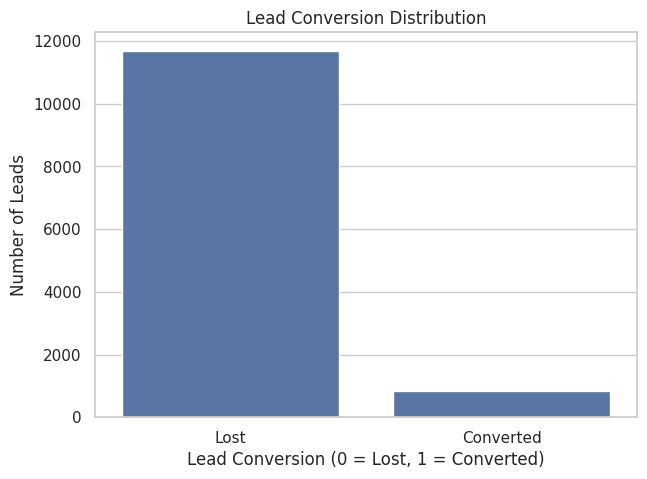

In [28]:
plt.figure(figsize=(7, 5))
sns.countplot(data=df,x='target')
plt.title('Lead Conversion Distribution')
plt.xlabel('Lead Conversion (0 = Lost, 1 = Converted)')
plt.ylabel('Number of Leads')
plt.xticks([0, 1], ['Lost', 'Converted'])
plt.show()

In [29]:
conversion_count = df['target'].value_counts()
print(conversion_count)


target
0    11698
1      845
Name: count, dtype: int64


In [30]:
conversion_percentage = (df['target'].value_counts(normalize=True) * 100)
print(conversion_percentage.round(2))

target
0    93.26
1     6.74
Name: proportion, dtype: float64


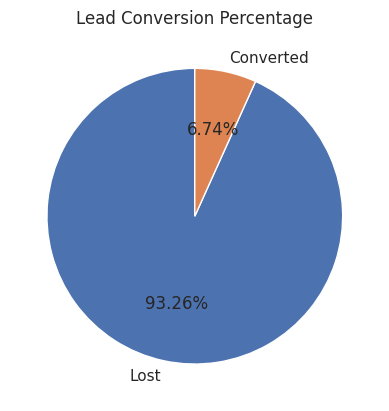

In [31]:
plt.pie(conversion_count,labels=['Lost', 'Converted'],autopct='%1.2f%%',startangle=90)
plt.title('Lead Conversion Percentage')
plt.show()

LEAD CONVERSION BY SOURCE TYPE

In [32]:
source_conversion = (df.groupby('source_type')['target'].mean().mul(100).sort_values(ascending=False))
print(source_conversion)

source_type
INSTAGRAM           7.509301
WALK_IN_LEAD        6.250000
FACEBOOK_ADS        6.005587
FILE_UPLOAD         3.305785
MOVE_LEAD           1.618705
NEODOVE_DIAL_PAD    0.000000
Name: target, dtype: float64


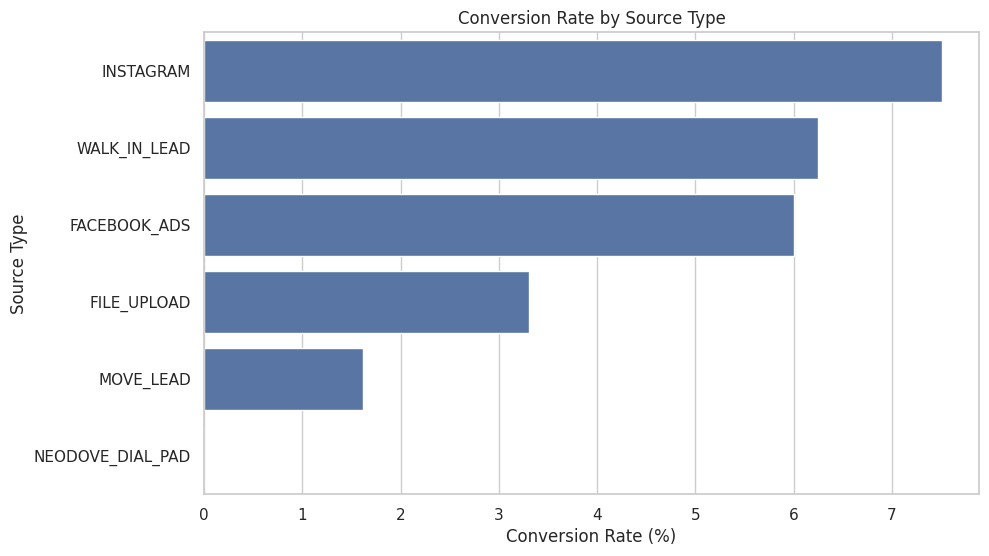

In [33]:
plt.figure(figsize=(10, 6))
sns.barplot(x=source_conversion.values,y=source_conversion.index)
plt.title('Conversion Rate by Source Type')
plt.xlabel('Conversion Rate (%)')
plt.ylabel('Source Type')
plt.show()

CONVERSION BY MARKETING CAMPAIGN

In [34]:
campaign_conversion = (df.groupby('campaign_name')['target'].mean().mul(100).sort_values(ascending=False))
print(campaign_conversion)

campaign_name
Business Accounting                     32.753623
Common Ads 21-08-2025                    5.769231
Refurbished Campaign- UI/UX              5.263158
IT DUMB                                  4.000000
DM NO-STIPEND-23-10-2025                 3.389831
UI/UX no Stipend                         3.260870
Python Knovista                          3.224277
Python Knovista New                      3.223640
Python Knovista No Stipend               2.976190
Performance Marketing Knovista           2.941176
Data Analytics Knovista                  2.898551
UI/UX Hiring                             2.527076
SAP COURSE - 20-10-2025                  2.479339
BA NEW 18-08-2025                        2.216253
BA NO STIPEND 28-10-2025                 2.040816
Refurbished Campaign-DA                  2.020202
Refurbished Campaign-BA                  1.955990
Refurbished Campaign                     1.929260
PHP Knovista                             1.851852
PHP Knovista New                    

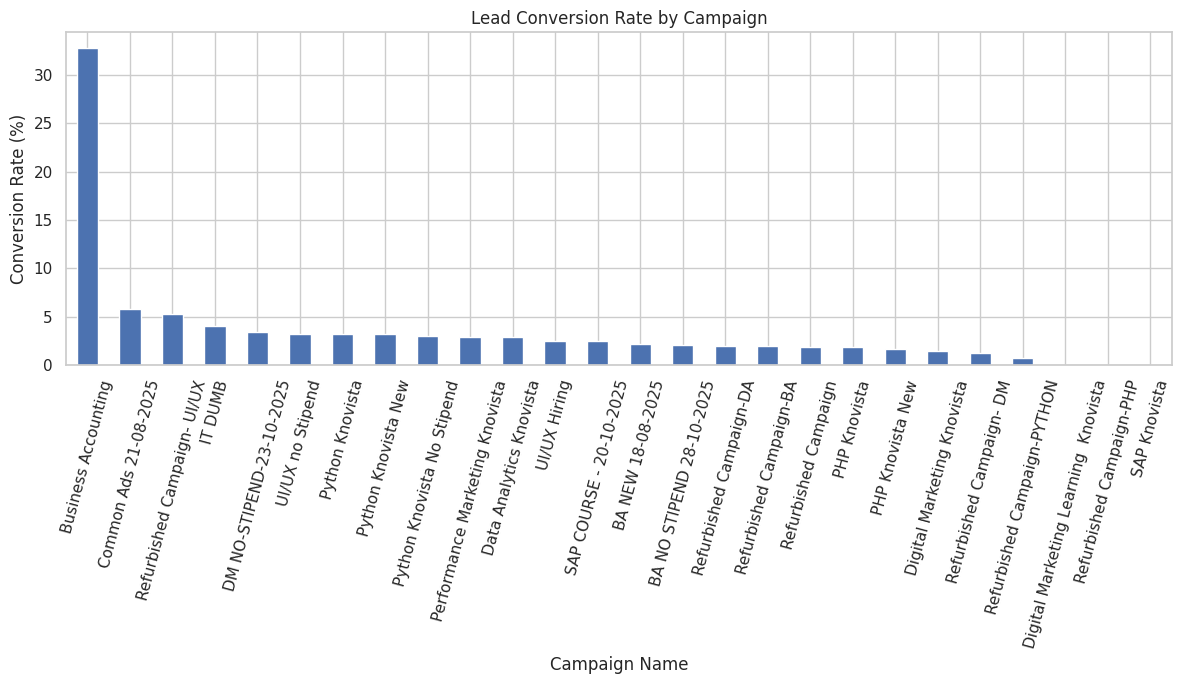

In [35]:
plt.figure(figsize=(12, 7))
campaign_conversion.plot(kind='bar')
plt.title('Lead Conversion Rate by Campaign')
plt.xlabel('Campaign Name')
plt.ylabel('Conversion Rate (%)')
plt.xticks(rotation=75)
plt.tight_layout()
plt.show()

CONVERSION BY LEAD TAG

In [36]:
tag_conversion = (df.groupby('lead_tag')['target'].mean().mul(100).sort_values(ascending=False))
print(tag_conversion)


lead_tag
already-purchased      0.0
call-not-connected     0.0
lost-to-competition    0.0
not-interested         0.0
Name: target, dtype: float64


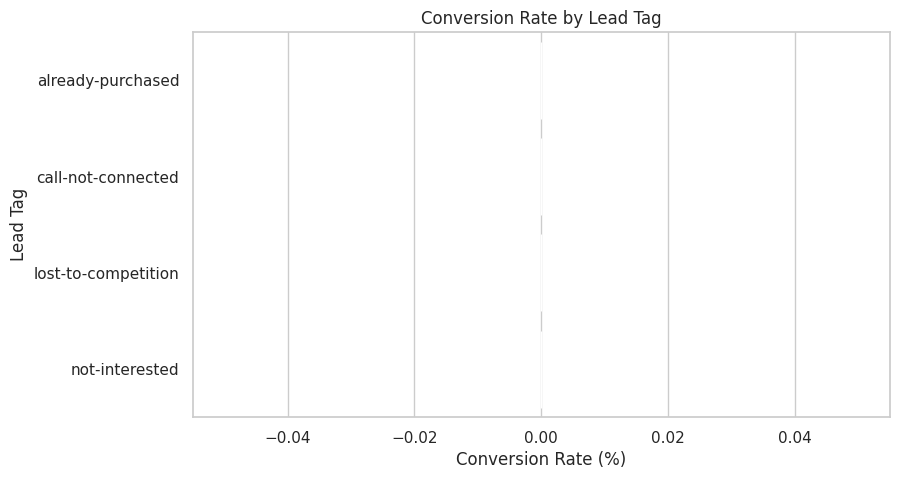

In [37]:
plt.figure(figsize=(9, 5))
sns.barplot(x=tag_conversion.values,y=tag_conversion.index)
plt.title('Conversion Rate by Lead Tag')
plt.xlabel('Conversion Rate (%)')
plt.ylabel('Lead Tag')
plt.show()

CONVERSION BY ASSIGNED SALES PERSON

In [38]:
sales_conversion = (df.groupby('assigned_to')['target'].agg(['mean', 'count']))
sales_conversion['Conversion Rate'] = (sales_conversion['mean'] * 100)
sales_conversion = sales_conversion.sort_values(by='Conversion Rate',ascending=False)
display(sales_conversion)


,mean,count,Conversion Rate
assigned_to,,,
Anshad,0.522066,1065,52.206573
Asiya,0.125000,16,12.500000
Sneha Rajesh,0.069620,158,6.962025
Megha S,0.042273,1443,4.227304
Revathy Reghu,0.038308,1253,3.830806
Ardra Shibu,0.033413,419,3.341289
Varsha A V,0.032000,125,3.200000
Devi Nandhana,0.028571,175,2.857143
VIJI,0.027574,544,2.757353


<Axes: xlabel='Conversion Rate', ylabel='assigned_to'>

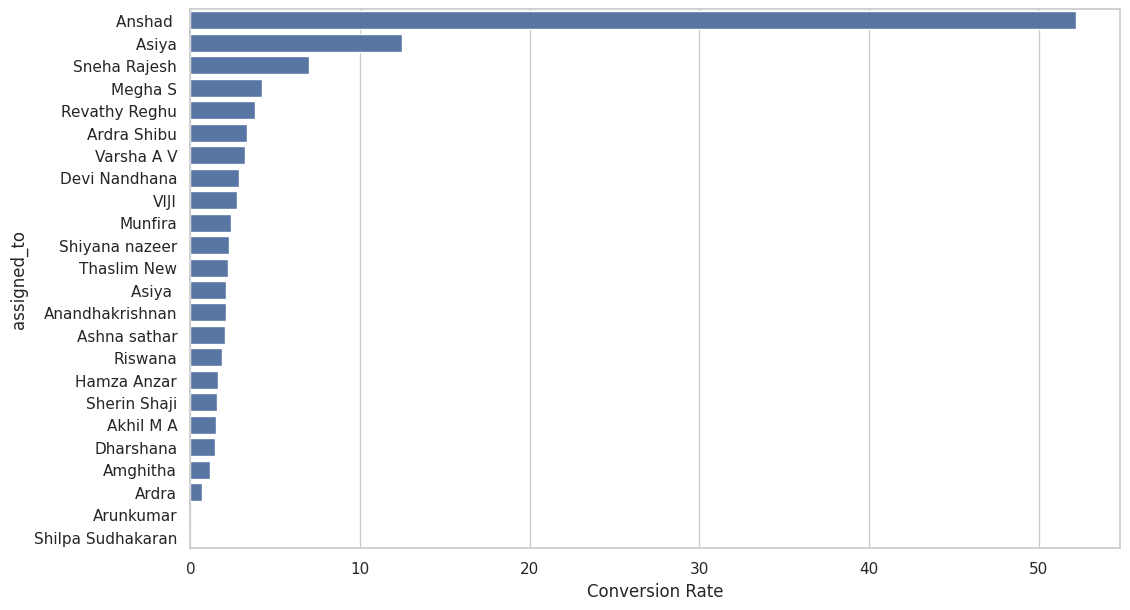

In [39]:
plt.figure(figsize=(12, 7))
sns.barplot(data=sales_conversion.reset_index(),x='Conversion Rate',y='assigned_to')

FEATURE ENGINEERING

In [44]:
df.columns = df.columns.str.strip()
print(df.columns.tolist())

['creation_date', 'first_call_attempt', 'lead_tag', 'assigned_to', 'campaign_name', 'source_type', 'source_name', 'target']


In [45]:
df['creation_date'] = pd.to_datetime(df['creation_date'],dayfirst=True,errors='coerce')
df['first_call_attempt'] = pd.to_datetime(df['first_call_attempt'],dayfirst=True,errors='coerce')
df['creation_year'] = df['creation_date'].dt.year
df['creation_month'] = df['creation_date'].dt.month
df['creation_day'] = df['creation_date'].dt.day
df['creation_hour'] = df['creation_date'].dt.hour
df['creation_weekday'] = df['creation_date'].dt.dayofweek
df['first_call_delay_hours'] = (df['first_call_attempt'] - df['creation_date']).dt.total_seconds() / 3600
df.drop(columns=['first_call_attempt'],inplace=True)
print("Feature Engineering Completed!")
display(df.head())


Feature Engineering Completed!


,creation_date,lead_tag,assigned_to,campaign_name,source_type,source_name,target,creation_year,creation_month,creation_day,creation_hour,creation_weekday,first_call_delay_hours
594,2025-12-25 10:06:00,not-interested,Dharshana,Data Analytics Knovista,INSTAGRAM,INSTAGRAM,0,2025,12,25,10,3,26.416667
607,2025-12-25 08:05:00,not-interested,Megha S,Data Analytics Knovista,FACEBOOK_ADS,FACEBOOK_ADS,0,2025,12,25,8,3,5.100000
614,2025-12-25 06:59:00,not-interested,Revathy Reghu,Data Analytics Knovista,INSTAGRAM,INSTAGRAM,0,2025,12,25,6,3,5.066667
616,2025-12-25 04:34:00,not-interested,Megha S,Data Analytics Knovista,INSTAGRAM,INSTAGRAM,0,2025,12,25,4,3,8.616667
637,2025-12-24 20:51:00,not-interested,Megha S,Data Analytics Knovista,INSTAGRAM,INSTAGRAM,0,2025,12,24,20,2,18.633333


CORRELATION ANALYSIS

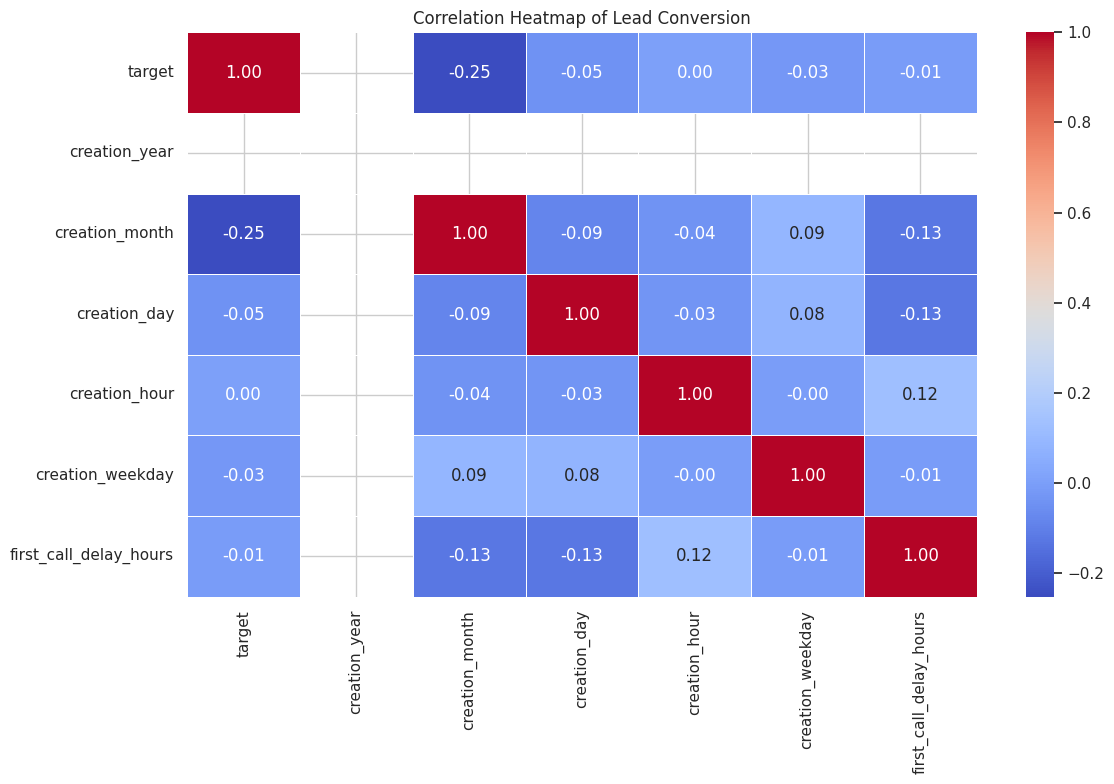

In [46]:
numeric_df = df.select_dtypes(include=np.number)
correlation_matrix = numeric_df.corr()
plt.figure(figsize=(12, 8))
sns.heatmap(correlation_matrix,annot=True,cmap='coolwarm',fmt='.2f',linewidths=0.5)
plt.title('Correlation Heatmap of Lead Conversion')
plt.tight_layout()
plt.show()

CREATE INDEPENDENT AND DEPENDENT VARIABLES

In [47]:
X = df.drop(columns=['target'])
y = df['target']

print("Independent Variables (X):")
print(X.columns.tolist())

print("\nDependent Variable (y):")
print(y.name)

Independent Variables (X):
['creation_date', 'lead_tag', 'assigned_to', 'campaign_name', 'source_type', 'source_name', 'creation_year', 'creation_month', 'creation_day', 'creation_hour', 'creation_weekday', 'first_call_delay_hours']

Dependent Variable (y):
target


In [48]:
print("\n X Shape:", X.shape)
print("y Shape:", y.shape)



 X Shape: (12543, 12)
y Shape: (12543,)


TRAIN TEST SPLIT

In [49]:
X_train, X_test, y_train, y_test = train_test_split(X,y,test_size=0.20,random_state=42,stratify=y)
print("X_train Shape:", X_train.shape)
print("X_test Shape:", X_test.shape)
print("y_train Shape:", y_train.shape)
print("y_test Shape:", y_test.shape)
print(y_train.value_counts(normalize=True))
print(y_test.value_counts(normalize=True))

X_train Shape: (10034, 12)
X_test Shape: (2509, 12)
y_train Shape: (10034,)
y_test Shape: (2509,)
target
0    0.932629
1    0.067371
Name: proportion, dtype: float64
target
0    0.932642
1    0.067358
Name: proportion, dtype: float64


DATA PREPROCESSING

In [50]:
numeric_features = X.select_dtypes(include=np.number).columns.tolist()
categorical_features = X.select_dtypes(exclude=np.number).columns.tolist()
print(numeric_features)
print(categorical_features)


['creation_year', 'creation_month', 'creation_day', 'creation_hour', 'creation_weekday', 'first_call_delay_hours']
['creation_date', 'lead_tag', 'assigned_to', 'campaign_name', 'source_type', 'source_name']


PREPROCESSING PIPELINE

In [51]:
numeric_transformer = Pipeline(steps=[('imputer', SimpleImputer(strategy='median')),('scaler', StandardScaler())])
categorical_transformer = Pipeline(steps=[('imputer', SimpleImputer(strategy='most_frequent')),('encoder', OneHotEncoder(handle_unknown='ignore'))])
preprocessor = ColumnTransformer(transformers=[('num', numeric_transformer, numeric_features),('cat', categorical_transformer, categorical_features)])
print("Preprocessing Pipeline Created Successfully!")


Preprocessing Pipeline Created Successfully!


MODEL DEVELOPMENT

LOGISTIC REGRESSION

In [52]:
logistic_model = Pipeline(steps=[('preprocessor', preprocessor),('classifier', LogisticRegression(class_weight='balanced',max_iter=2000,random_state=42))])
logistic_model.fit(X_train, y_train)
logistic_predictions = logistic_model.predict(X_test)
print("Logistic Regression Training Completed!")


Logistic Regression Training Completed!


DECISION TREE CLASSIFIER

In [53]:
decision_tree_model = Pipeline(steps=[('preprocessor', preprocessor),('classifier', DecisionTreeClassifier(class_weight='balanced',max_depth=8,min_samples_leaf=10,random_state=4 ))])
decision_tree_model.fit(X_train, y_train)
decision_tree_predictions = decision_tree_model.predict(X_test)
print("Decision Tree Training Completed!")



Decision Tree Training Completed!


RANDOM FOREST CLASSIFIER

In [54]:
random_forest_model = Pipeline(steps=[('preprocessor', preprocessor),('classifier', RandomForestClassifier(n_estimators=200,max_depth=12,min_samples_leaf=5,class_weight='balanced_subsample',random_state=42,n_jobs=-1))])
random_forest_model.fit(X_train, y_train)
random_forest_predictions = random_forest_model.predict(X_test)
print("Random Forest Training Completed!")


Random Forest Training Completed!


MODEL EVALUATION

In [58]:
models = {'Logistic Regression': logistic_model,'Decision Tree': decision_tree_model,'Random Forest': random_forest_model}
results = []
for model_name, model in models.items():
  predictions = model.predict(X_test)
  probabilities = model.predict_proba(X_test)[:, 1]
  accuracy = accuracy_score(y_test, predictions)
  precision = precision_score(
  y_test, predictions, zero_division=0)
  recall = recall_score(y_test, predictions, zero_division=0)
  f1 = f1_score(y_test, predictions, zero_division=0)
  roc_auc = roc_auc_score(y_test, probabilities)
  results.append({'Model': model_name,'Accuracy': accuracy,'Precision': precision,'Recall': recall,'F1 Score': f1,'ROC-AUC': roc_auc})

results_df = pd.DataFrame(results)
display(results_df.sort_values(by='ROC-AUC',ascending=False).round(4))

,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC
0,Logistic Regression,0.9322,0.4977,0.6331,0.5573,0.8526
1,Decision Tree,0.8908,0.3433,0.6805,0.4563,0.8346
2,Random Forest,0.8545,0.2633,0.6450,0.3739,0.8270


MODEL COMPARISON VISUALIZATION

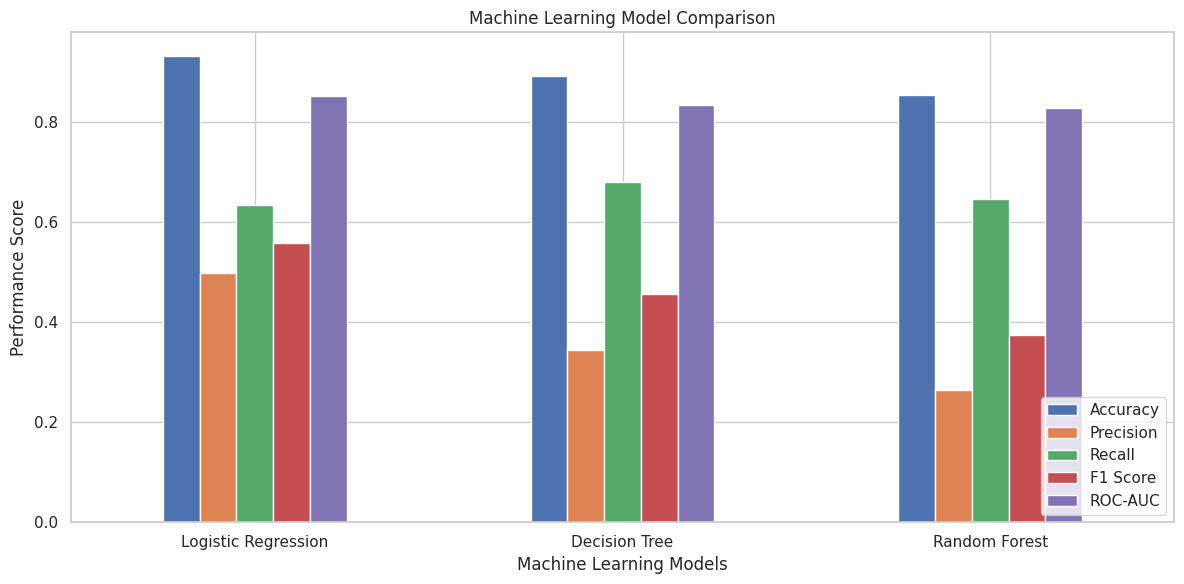

In [59]:
metrics = ['Accuracy','Precision','Recall','F1 Score','ROC-AUC']
results_plot = results_df.set_index('Model')[metrics]
results_plot.plot(kind='bar',figsize=(12, 6))
plt.title('Machine Learning Model Comparison')
plt.ylabel('Performance Score')
plt.xlabel('Machine Learning Models')
plt.xticks(rotation=0)
plt.legend(loc='lower right')
plt.tight_layout()

CONFUSION MATRIX

In [60]:
best_model_name = (results_df.sort_values(by='ROC-AUC',ascending=False).iloc[0]['Model'])
best_model = models[best_model_name]
best_predictions = best_model.predict(X_test)
print("Best Model:", best_model_name)
print("\nClassification Report:")
print(classification_report(y_test,best_predictions,target_names=['Lost', 'Converted'],zero_division=0))

Best Model: Logistic Regression

Classification Report:
              precision    recall  f1-score   support

        Lost       0.97      0.95      0.96      2340
   Converted       0.50      0.63      0.56       169

    accuracy                           0.93      2509
   macro avg       0.74      0.79      0.76      2509
weighted avg       0.94      0.93      0.94      2509



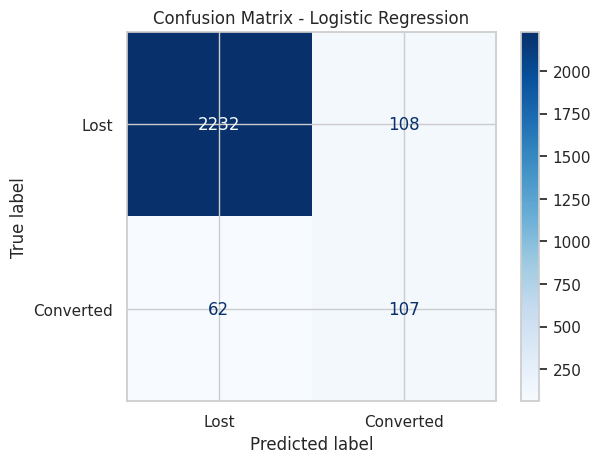

In [61]:
cm = confusion_matrix( y_test,best_predictions)
disp = ConfusionMatrixDisplay(confusion_matrix=cm,display_labels=['Lost', 'Converted'])
disp.plot(cmap='Blues')
plt.title(f'Confusion Matrix - {best_model_name}')
plt.show()

ROC CURVE

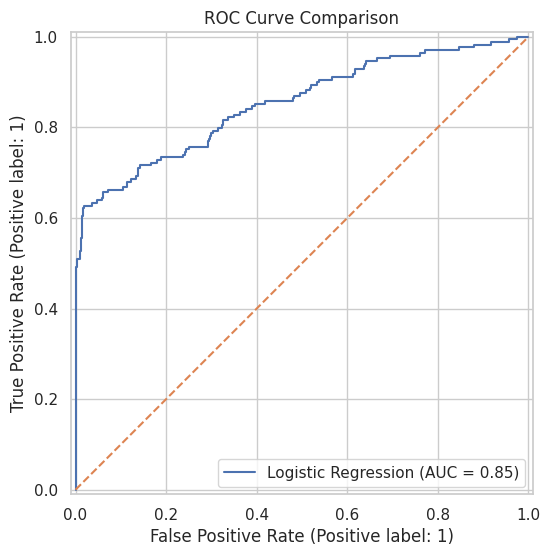

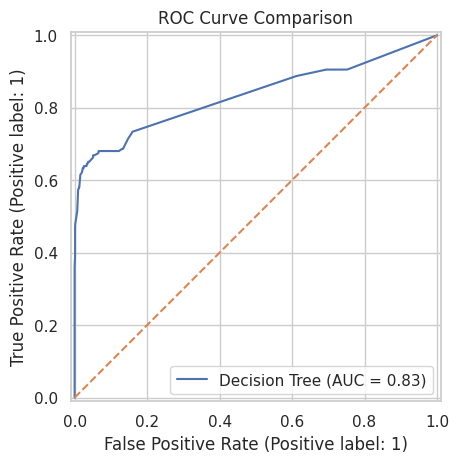

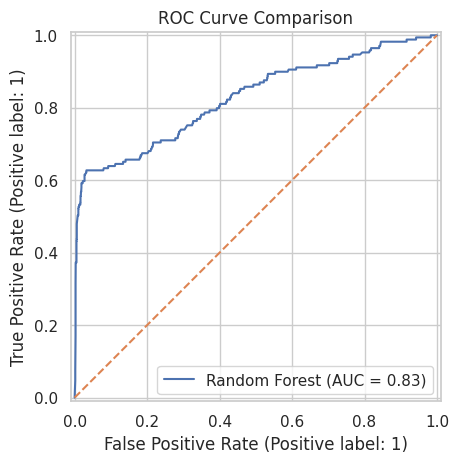

In [62]:
plt.figure(figsize=(8, 6))
for model_name, model in models.items():
  RocCurveDisplay.from_estimator(model,X_test,y_test,name=model_name,ax=plt.gca())
  plt.title('ROC Curve Comparison')
  plt.plot(
    [0, 1],
    [0, 1],
    linestyle='--')
  plt.show()

SELECT THE BEST MODEL

In [63]:
best_row = results_df.loc[results_df['ROC-AUC'].idxmax()]
print("BEST PERFORMING MODEL")
print("Model:", best_row['Model'])
print("Accuracy:", round(best_row['Accuracy'], 4))
print("Precision:", round(best_row['Precision'], 4))
print("Recall:", round(best_row['Recall'], 4))
print("F1 Score:", round(best_row['F1 Score'], 4))
print("ROC-AUC:", round(best_row['ROC-AUC'], 4))

BEST PERFORMING MODEL
Model: Logistic Regression
Accuracy: 0.9322
Precision: 0.4977
Recall: 0.6331
F1 Score: 0.5573
ROC-AUC: 0.8526


FEATURE IMPORTANCE ANALYSIS

In [64]:
rf_classifier = random_forest_model.named_steps['classifier']
feature_names = (random_forest_model.named_steps['preprocessor'].get_feature_names_out())
importance_values = rf_classifier.feature_importances_
importance_df = pd.DataFrame({'Feature': feature_names,'Importance': importance_values})
importance_df = importance_df.sort_values(by='Importance',ascending=False)
display(importance_df.head(15))


,Feature,Importance
1,num__creation_month,0.063288
9365,cat__assigned_to_Anandhakrishnan,0.054212
2,num__creation_day,0.041443
9366,cat__assigned_to_Anshad,0.039338
9432,cat__source_name_MOVE_LEAD,0.037649
9378,cat__assigned_to_Riswana,0.033438
9392,cat__campaign_name_Digital Marketing Knovista,0.029296
9428,cat__source_name_INSTAGRAM,0.028434
9398,cat__campaign_name_Python Knovista,0.027773
9373,cat__assigned_to_Dharshana,0.022237


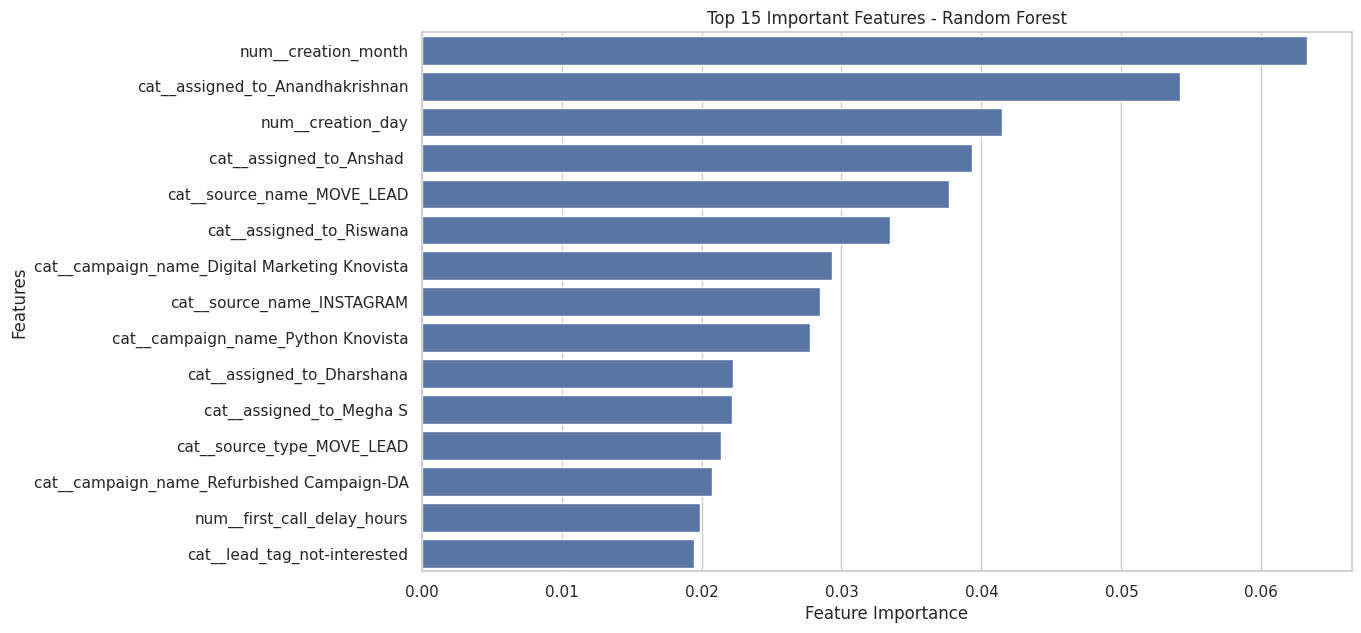

In [65]:
plt.figure(figsize=(12, 7))
sns.barplot(data=importance_df.head(15),x='Importance',y='Feature')
plt.title('Top 15 Important Features - Random Forest')
plt.xlabel('Feature Importance')
plt.ylabel('Features')
plt.show()

BUILD THE LEAD CONVERSION PREDICTION SYSYEM

CREATE A NEW LEAD

In [66]:
new_lead = pd.DataFrame([{'campaign_name': 'Data Analytics Knovista','source_type': 'INSTAGRAM','source_name': 'INSTAGRAM','assigned_to': 'Anshad','lead_tag': 'hot','creation_year': 2026,'creation_month': 11,'creation_day': 14,'creation_hour': 10,'creation_weekday': 5,'first_call_delay_hours': 1.5}])
new_lead = new_lead.reindex(
    columns=X.columns)
print("New Lead Information:")
display(new_lead)

New Lead Information:


,creation_date,lead_tag,assigned_to,campaign_name,source_type,source_name,creation_year,creation_month,creation_day,creation_hour,creation_weekday,first_call_delay_hours
0,NaN,hot,Anshad,Data Analytics Knovista,INSTAGRAM,INSTAGRAM,2026,11,14,10,5,1.5


PREDICT LEAD CONVERSION

In [67]:
prediction = best_model.predict(new_lead)[0]
conversion_probability = (best_model.predict_proba(new_lead)[0][1])
print("LEAD CONVERSION PREDICTION")
if prediction == 1:
    print("Prediction: Lead is likely to CONVERT")
else:
    print("Prediction: Lead is likely to be LOST")
print("Conversion Probability:",round(conversion_probability * 100, 2),"%")
print("Lost Probability:",round((1 - conversion_probability) * 100, 2),"%")

LEAD CONVERSION PREDICTION
Prediction: Lead is likely to be LOST
Conversion Probability: 2.2 %
Lost Probability: 97.8 %


DISPLAY PREDICTION RESULT

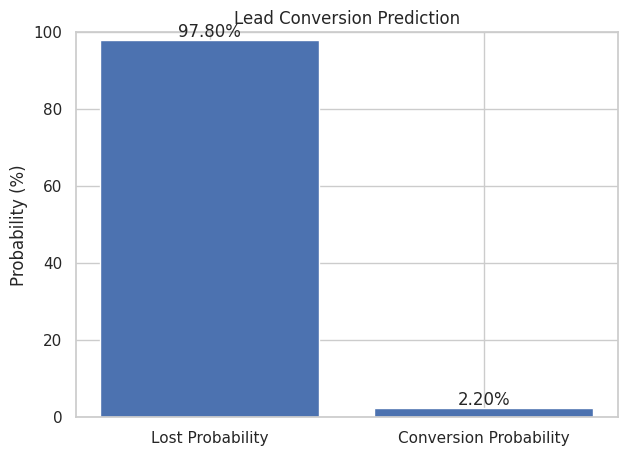

In [68]:
labels = ['Lost Probability', 'Conversion Probability']
values = [(1 - conversion_probability) * 100,conversion_probability * 100]
plt.figure(figsize=(7, 5))
plt.bar(labels,values)
plt.title('Lead Conversion Prediction')
plt.ylabel('Probability (%)')
plt.ylim(0, 100)
for i, value in enumerate(values):
    plt.text(i,value + 1,f'{value:.2f}%',ha='center')
plt.show()

SAVE THE TRAINED MACHINE LEARNING MODEL

In [69]:
import joblib
joblib.dump(best_model,'lead_conversion_model.pkl')
print("Model saved successfully!")
from google.colab import files
files.download('lead_conversion_model.pkl')

Model saved successfully!


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [70]:
loaded_model = joblib.load('lead_conversion_model.pkl')
print("Saved model loaded successfully!")

Saved model loaded successfully!
